# **Phase 3 - Vehicle Classification**

**Students:** Samarth Kale, Saarth Kishore

This is an open ended phase. You must build a classifier for the Stanford Cars Dataset. You can use any techniques and knowledge from Phase 1 & 2 to aid you. The ultimate goal is to get as good performance as you can on the test set.

Please follow TA instructions in lab to learn how to access the data.


# **Imports**

Import all the libraries you need for your project. Google Drive mounting code is provided if you plan to use Colab.

In [3]:
# from google.colab import drive
# drive.mount('/content/drive')

In [4]:
# ---- ONE-TIME SETUP: build train_make.csv / test_make.csv from the repo's .mat files ----
import os
import pandas as pd
import scipy.io as sio

CARS_ROOT = r'C:\ml\stanford_cars'   # folder that contains cars_train, cars_test, devkit

# Makes whose names are more than one word; everything else is the first word of the class name
MULTI_WORD_MAKES = ['AM General', 'Aston Martin', 'Land Rover']

def get_make(class_name):
    for m in MULTI_WORD_MAKES:
        if class_name.startswith(m + ' '):
            return m
    return class_name.split(' ')[0]

meta = sio.loadmat(os.path.join(CARS_ROOT, 'devkit', 'cars_meta.mat'), squeeze_me=True)
class_names = [str(n) for n in meta['class_names']]

def mat_to_df(mat_path):
    annos = sio.loadmat(mat_path, squeeze_me=True)['annotations']
    rows = []
    for a in annos:
        cls_id = int(a['class']) - 1                      # .mat labels are 1-indexed
        name = class_names[cls_id]
        rows.append({'image': str(a['fname']), 'make': get_make(name),
                     'class_name': name, 'class_id': cls_id,
                     'x1': int(a['bbox_x1']), 'y1': int(a['bbox_y1']),
                     'x2': int(a['bbox_x2']), 'y2': int(a['bbox_y2'])})
    return pd.DataFrame(rows)

train_df_out = mat_to_df(os.path.join(CARS_ROOT, 'devkit', 'cars_train_annos.mat'))
test_df_out = mat_to_df(os.path.join(CARS_ROOT, 'cars_test_annos_withlabels.mat'))
train_df_out.to_csv(os.path.join(CARS_ROOT, 'train_make.csv'), index=False)
test_df_out.to_csv(os.path.join(CARS_ROOT, 'test_make.csv'), index=False)

print(f'train: {len(train_df_out)} images | test: {len(test_df_out)} images | makes: {train_df_out.make.nunique()}')
print(sorted(train_df_out.make.unique()))

train: 8144 images | test: 8041 images | makes: 49
['AM General', 'Acura', 'Aston Martin', 'Audi', 'BMW', 'Bentley', 'Bugatti', 'Buick', 'Cadillac', 'Chevrolet', 'Chrysler', 'Daewoo', 'Dodge', 'Eagle', 'FIAT', 'Ferrari', 'Fisker', 'Ford', 'GMC', 'Geo', 'HUMMER', 'Honda', 'Hyundai', 'Infiniti', 'Isuzu', 'Jaguar', 'Jeep', 'Lamborghini', 'Land Rover', 'Lincoln', 'MINI', 'Maybach', 'Mazda', 'McLaren', 'Mercedes-Benz', 'Mitsubishi', 'Nissan', 'Plymouth', 'Porsche', 'Ram', 'Rolls-Royce', 'Scion', 'Spyker', 'Suzuki', 'Tesla', 'Toyota', 'Volkswagen', 'Volvo', 'smart']


In [5]:
import os
import time
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

# ---- Paths (edit to match the TA-provided data layout) ----
DATA_ROOT = r'C:\ml\stanford_cars'
TRAIN_IMG_DIR = os.path.join(DATA_ROOT, 'cars_train')
TEST_IMG_DIR = os.path.join(DATA_ROOT, 'cars_test')
TRAIN_CSV = os.path.join(DATA_ROOT, 'train_make.csv')
TEST_CSV = os.path.join(DATA_ROOT, 'test_make.csv')

IMG_SIZE = 224
NUM_WORKERS = 0   # keep 0 for Jupyter on Windows; 2-4 is fine on Colab/Linux

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Quick look at the CSV so you can confirm the column names used below
print(pd.read_csv(TRAIN_CSV).head())

Using device: cuda:0
       image     make                           class_name  class_id   x1  \
0  00001.jpg     Audi                  Audi TTS Coupe 2012        13   39   
1  00002.jpg    Acura                  Acura TL Sedan 2012         2   36   
2  00003.jpg    Dodge           Dodge Dakota Club Cab 2007        90   85   
3  00004.jpg  Hyundai     Hyundai Sonata Hybrid Sedan 2012       133  621   
4  00005.jpg     Ford  Ford F-450 Super Duty Crew Cab 2012       105   14   

    y1    x2    y2  
0  116   569   375  
1  116   868   587  
2  109   601   381  
3  393  1484  1096  
4   36   133    99  


**Data setup:** Data comes from the TA-approved repo https://github.com/jhpohovey/StanfordCars. The first code cell converts its .mat annotations into train_make.csv and test_make.csv, labeling each image by car make (49 classes) taken from the class name (e.g. "Audi S5 Coupe 2012" -> "Audi"). To grade, set the three paths at the top of Section 7 (test images folder, test CSV with an image-filename column and a "make" column, and vehicle_classifier.pth), then run that cell on its own.

# **1. Load Dataset**
The Stanford Dataset is provided in ```torchvision.datasets```. However, you must code your own Dataset class to load the dataset.

You will need to create your inherit from ```Dataset``` class to load the dataset and overload the ```___init__()```, ```__len__()```, and ```__getitem__()``` functions.

You will find the [following link](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html) useful to help create the dataset class.

Please also create another function or method in the class: ```show_imgs()``` to help visualize the data. Similar to Phase 1 and 2, you need to display random images and label. Please display 3-5 unique classes.

In [6]:
def _find_columns(df, img_col=None, label_col=None):
    """Picks the image-filename and label columns if they are not given explicitly."""
    if img_col is None:
        for c in df.columns:
            if df[c].astype(str).str.lower().str.endswith(('.jpg', '.jpeg', '.png')).all():
                img_col = c
                break
    if label_col is None:
        for c in ['make', 'label', 'class', 'class_name', 'Make', 'Label', 'Class']:
            if c in df.columns:
                label_col = c
                break
        else:
            label_col = [c for c in df.columns if c != img_col][-1]
    assert img_col is not None, f'Could not find an image filename column in {list(df.columns)}'
    return img_col, label_col


class CarDataSet(Dataset):
    """Stanford Cars dataset read from an image folder + a CSV of (filename, label).

    annotations: path to a CSV, or a pandas DataFrame (used for the train/val split)
    classes:     list of class names; pass the training set's list to val/test sets so the
                 label -> index mapping is identical everywhere
    """

    def __init__(self, img_dir, annotations, transform=None, classes=None, img_col=None, label_col=None):
        self.img_dir = img_dir
        self.df = pd.read_csv(annotations) if isinstance(annotations, str) else annotations.reset_index(drop=True)
        self.img_col, self.label_col = _find_columns(self.df, img_col, label_col)
        self.transform = transform

        self.classes = list(classes) if classes is not None else sorted(self.df[self.label_col].unique().tolist())
        self.class_to_idx = {c: i for i, c in enumerate(self.classes)}
        self.labels = [self.class_to_idx[l] for l in self.df[self.label_col]]

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        path = os.path.join(self.img_dir, os.path.basename(str(self.df.loc[idx, self.img_col])))
        img = Image.open(path).convert('RGB')     # some Stanford Cars images are grayscale
        if self.transform is not None:
            img = self.transform(img)
        return img, self.labels[idx]

    def show_imgs(self, num_classes=4, per_class=1):
        """Displays random images from `num_classes` distinct random classes with their labels."""
        labels = np.array(self.labels)
        chosen = random.sample(sorted(set(labels.tolist())), num_classes)
        n = num_classes * per_class
        fig, axes = plt.subplots(1, n, figsize=(4 * n, 3.5))
        axes = np.atleast_1d(axes)
        k = 0
        for c in chosen:
            for idx in np.random.choice(np.where(labels == c)[0], per_class, replace=False):
                img, label = self[idx]
                axes[k].imshow(denormalize(img) if torch.is_tensor(img) else img)
                axes[k].set_title(str(self.classes[label]))
                axes[k].axis('off')
                k += 1
        plt.tight_layout()
        plt.show()


CarsDataset = CarDataSet   # Section 7 template uses this name


def denormalize(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


# Train-time augmentation: images are squashed to a square first (cars are wide, so a center
# crop would cut off the front/back), then randomly cropped, flipped and color-jittered.
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.85, 1.15)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.15)),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

In [7]:
# Load the Data
# Hold out 10% of the training CSV (stratified by class) as a validation set for curves/tuning.
full_df = pd.read_csv(TRAIN_CSV)
_img_col, _label_col = _find_columns(full_df)
train_df, val_df = train_test_split(full_df, test_size=0.10, stratify=full_df[_label_col], random_state=SEED)

train_data = CarDataSet(TRAIN_IMG_DIR, train_df, transform=train_transform)
classes = train_data.classes
num_classes = len(classes)
val_data = CarDataSet(TRAIN_IMG_DIR, val_df, transform=eval_transform, classes=classes)
test_data = CarDataSet(TEST_IMG_DIR, TEST_CSV, transform=eval_transform, classes=classes)

print(f'{num_classes} classes | train {len(train_data)} | val {len(val_data)} | test {len(test_data)}')

# Batch Size
batch_size = 32

# Import to Dataloaders
pin = device.type == 'cuda'
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS, pin_memory=pin, drop_last=True)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)

test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)

49 classes | train 7329 | val 815 | test 8041


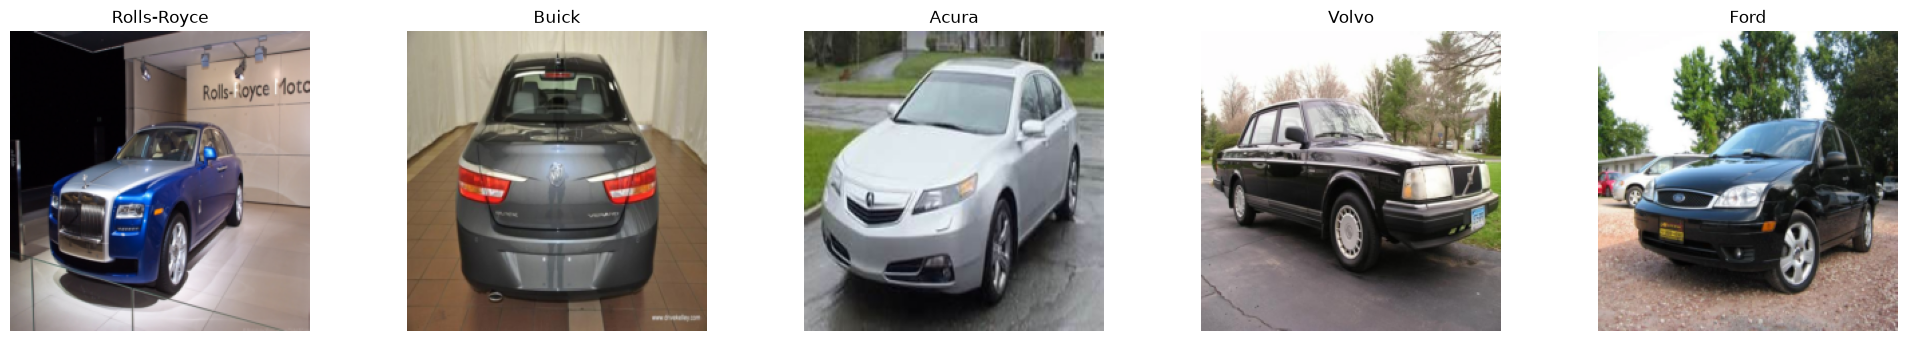

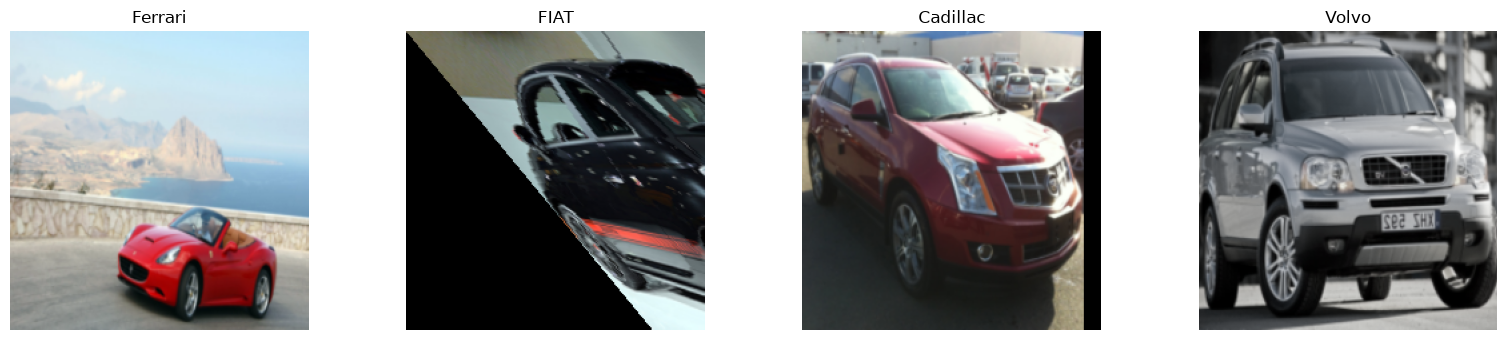

In [8]:
def show_imgs(dataset, num_classes=4, per_class=1):
    """Wrapper around CarDataSet.show_imgs: random images from 3-5 unique classes with labels."""
    dataset.show_imgs(num_classes=num_classes, per_class=per_class)

# Un-augmented view of the data
show_imgs(CarDataSet(TRAIN_IMG_DIR, train_df, transform=eval_transform, classes=classes), num_classes=5)
# Same idea with training augmentations applied
show_imgs(train_data, num_classes=4)

# **2. Define your Model Architecture**

It is up to you to decide which model you use. You can create your own CNN or use transfer learning.

In [9]:
# Model definition
# Transfer learning from ConvNeXt-Tiny pretrained on ImageNet-1k (~28M params, 82.5% top-1).
# It is a strong fine-grained backbone that still trains comfortably on a single consumer GPU.
def build_model(num_classes, pretrained=True):
    weights = ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if pretrained else None
    model = convnext_tiny(weights=weights)
    in_features = model.classifier[2].in_features            # 768
    model.classifier[2] = nn.Linear(in_features, num_classes)  # replace the 1000-class head
    return model

model = build_model(num_classes)

# Load Model onto GPU
model = model.to(device)
print(f'Params: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M')

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to C:\Users\Samarth/.cache\torch\hub\checkpoints\convnext_tiny-983f1562.pth


100.0%


Params: 27.9M


# **3. Define Optimizer, Scheduler, Loss, etc.**

You chose the loss function and optimizer.

In [10]:
num_epochs = 20

# Loss Function
# Label smoothing helps fine-grained classes that look nearly identical (reduces over-confidence).
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)

# Optimizer
# AdamW with a lower lr for the pretrained backbone and a higher lr for the new head.
head_params = list(model.classifier.parameters())
head_ids = {id(p) for p in head_params}
backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
optimizer = torch.optim.AdamW([
    {'params': backbone_params, 'lr': 1e-4},
    {'params': head_params, 'lr': 1e-3},
], weight_decay=0.05)

# Scheduler: 1 epoch linear warmup, then cosine decay (stepped every iteration)
steps_per_epoch = len(train_loader)
warmup_steps = steps_per_epoch
total_steps = num_epochs * steps_per_epoch
def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + np.cos(np.pi * progress))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

# Mixed precision for speed / memory on GPU
scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))

C:\Users\Samarth\AppData\Local\Temp\ipykernel_57144\1592921834.py:29: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))


# **4. Train your Network**

Feel free to use your `train()` from either Phase 1 or Phase 2, whichever you feel is a better choice to understand training to tune it better. Please make sure to plot your learning curves, for both loss and accuracy! Again, this can be per iterations or epoch depending on what you see fit. You will need to save your model as `.pth` file! [This link](https://pytorch.org/tutorials/beginner/saving_loading_models.html) will be useful.

In [11]:
# Train Network
WEIGHTS_PATH = 'vehicle_classifier.pth'

def evaluate(model, loader, loss_fn, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                outputs = model(images)
                loss = loss_fn(outputs, labels)
            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return running_loss / total, 100 * correct / total


def train(model, loss_fn, optimizer, scheduler, scaler, train_loader, val_loader, num_epochs, device, save_path):
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_acc = 0.0
    for epoch in range(num_epochs):
        start = time.time()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                outputs = model(images)
                loss = loss_fn(outputs, labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        train_loss, train_acc = running_loss / total, 100 * correct / total
        val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)
        for k, v in zip(history, [train_loss, train_acc, val_loss, val_acc]):
            history[k].append(v)

        tag = ''
        if val_acc > best_acc:
            best_acc = val_acc
            # Save the class list with the weights so the label mapping travels with the model
            torch.save({'model_state_dict': model.state_dict(), 'classes': classes,
                        'arch': 'convnext_tiny', 'img_size': IMG_SIZE}, save_path)
            tag = '  <- saved'
        print(f'Epoch [{epoch + 1}/{num_epochs}]  '
              f'Train Loss: {train_loss:.4f}  Train Acc: {train_acc:.2f}%  |  '
              f'Val Loss: {val_loss:.4f}  Val Acc: {val_acc:.2f}%  |  '
              f'lr {optimizer.param_groups[0]["lr"]:.2e}  |  {time.time() - start:.0f}s{tag}')
    print(f'Best val accuracy: {best_acc:.2f}%')
    return history

history = train(model, loss_fn, optimizer, scheduler, scaler, train_loader, val_loader, num_epochs, device, WEIGHTS_PATH)

# Reload the best checkpoint for evaluation
ckpt = torch.load(WEIGHTS_PATH, map_location=device)
model.load_state_dict(ckpt['model_state_dict'])

Epoch [1/20]  Train Loss: 3.0724  Train Acc: 23.88%  |  Val Loss: 1.9319  Val Acc: 63.19%  |  lr 1.00e-04  |  151s  <- saved
Epoch [2/20]  Train Loss: 1.6793  Train Acc: 69.23%  |  Val Loss: 1.2685  Val Acc: 83.19%  |  lr 9.93e-05  |  117s  <- saved
Epoch [3/20]  Train Loss: 1.2465  Train Acc: 84.66%  |  Val Loss: 1.1159  Val Acc: 88.47%  |  lr 9.73e-05  |  122s  <- saved
Epoch [4/20]  Train Loss: 1.0826  Train Acc: 90.37%  |  Val Loss: 1.0187  Val Acc: 91.17%  |  lr 9.40e-05  |  118s  <- saved
Epoch [5/20]  Train Loss: 1.0053  Train Acc: 92.77%  |  Val Loss: 0.9784  Val Acc: 92.39%  |  lr 8.95e-05  |  123s  <- saved
Epoch [6/20]  Train Loss: 0.9534  Train Acc: 94.15%  |  Val Loss: 0.9756  Val Acc: 92.39%  |  lr 8.39e-05  |  122s
Epoch [7/20]  Train Loss: 0.9158  Train Acc: 95.10%  |  Val Loss: 0.9287  Val Acc: 93.62%  |  lr 7.73e-05  |  119s  <- saved
Epoch [8/20]  Train Loss: 0.8800  Train Acc: 96.14%  |  Val Loss: 0.9016  Val Acc: 94.97%  |  lr 7.01e-05  |  117s  <- saved
Epoch [9/2

<All keys matched successfully>

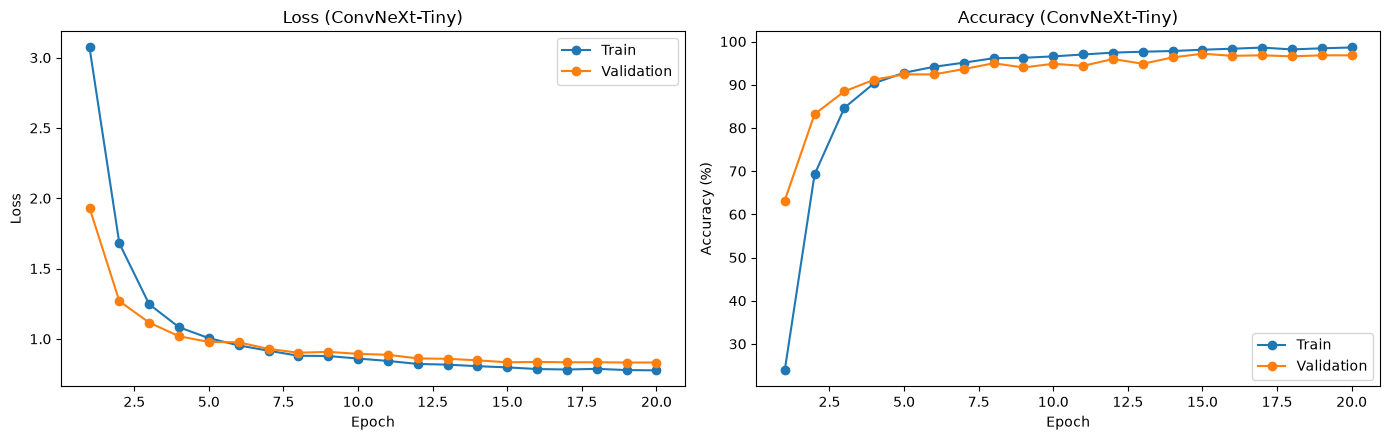

In [12]:
# Plot learning curves
def plot_learning_curve(history, title=''):
    epochs = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(epochs, history['train_loss'], 'o-', label='Train')
    axes[0].plot(epochs, history['val_loss'], 'o-', label='Validation')
    axes[0].set_title(f'Loss {title}'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend()
    axes[1].plot(epochs, history['train_acc'], 'o-', label='Train')
    axes[1].plot(epochs, history['val_acc'], 'o-', label='Validation')
    axes[1].set_title(f'Accuracy {title}'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy (%)'); axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_learning_curve(history, title='(ConvNeXt-Tiny)')
# Note: train accuracy is measured on augmented images with label smoothing, so it can sit
# below validation accuracy early on; that is expected, not a bug.

# **5. Evaluate**

Now we will evaluate on validation set. The TA's will run your model on the hold-out test set for your final grade.

## **5.1 Average and Per-class Accuracy**

Feel free to use `test_accuracy()` here to get accuracy. You also must show per-class accuracy. You can write your own accuracy function to get per class accuracy or use `classification_report` from `sklearn`.

In [13]:
def get_predictions(model, loader, device):
    """Returns true labels, predicted labels and softmax probabilities in loader order."""
    model.eval()
    all_labels, all_probs = [], []
    with torch.no_grad():
        for images, labels in loader:
            with torch.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                outputs = model(images.to(device))
            all_probs.append(torch.softmax(outputs.float(), dim=1).cpu())
            all_labels.append(labels)
    probs = torch.cat(all_probs)
    return torch.cat(all_labels).numpy(), probs.argmax(1).numpy(), probs.numpy()

def test_accuracy(model, loader, device):
    y_true, y_pred, _ = get_predictions(model, loader, device)
    acc = 100 * (y_true == y_pred).mean()
    print(f'Accuracy: {acc:.2f}%')
    return acc

# Evaluate on the validation split (labels may be hidden on the TA test set)
y_true, y_pred, y_prob = get_predictions(model, val_loader, device)
print(f'Average validation accuracy: {100 * (y_true == y_pred).mean():.2f}%\n')

# Per-class accuracy (= recall for each class)
print(classification_report(y_true, y_pred, labels=range(num_classes),
                            target_names=[str(c) for c in classes], digits=3, zero_division=0))

per_class = pd.DataFrame({
    'class': classes,
    'accuracy': [(y_pred[y_true == i] == i).mean() if (y_true == i).any() else np.nan for i in range(num_classes)],
    'support': [(y_true == i).sum() for i in range(num_classes)],
}).sort_values('accuracy')
print('Lowest-accuracy classes:')
print(per_class.head(10).to_string(index=False))



Average validation accuracy: 97.18%

               precision    recall  f1-score   support

   AM General      1.000     1.000     1.000         5
        Acura      1.000     0.958     0.979        24
 Aston Martin      0.938     0.938     0.938        16
         Audi      0.983     1.000     0.992        59
          BMW      0.981     1.000     0.991        53
      Bentley      1.000     1.000     1.000        24
      Bugatti      1.000     1.000     1.000         8
        Buick      0.941     1.000     0.970        16
     Cadillac      1.000     0.923     0.960        13
    Chevrolet      0.946     0.967     0.957        91
     Chrysler      0.960     0.923     0.941        26
       Daewoo      0.800     1.000     0.889         4
        Dodge      0.969     0.984     0.976        63
        Eagle      1.000     1.000     1.000         5
         FIAT      1.000     1.000     1.000         6
      Ferrari      1.000     1.000     1.000        16
       Fisker      1.000   

## **5.2 Confusion Matrix**

Please plot the confusion matrix with all classess. Please make this visually readable.

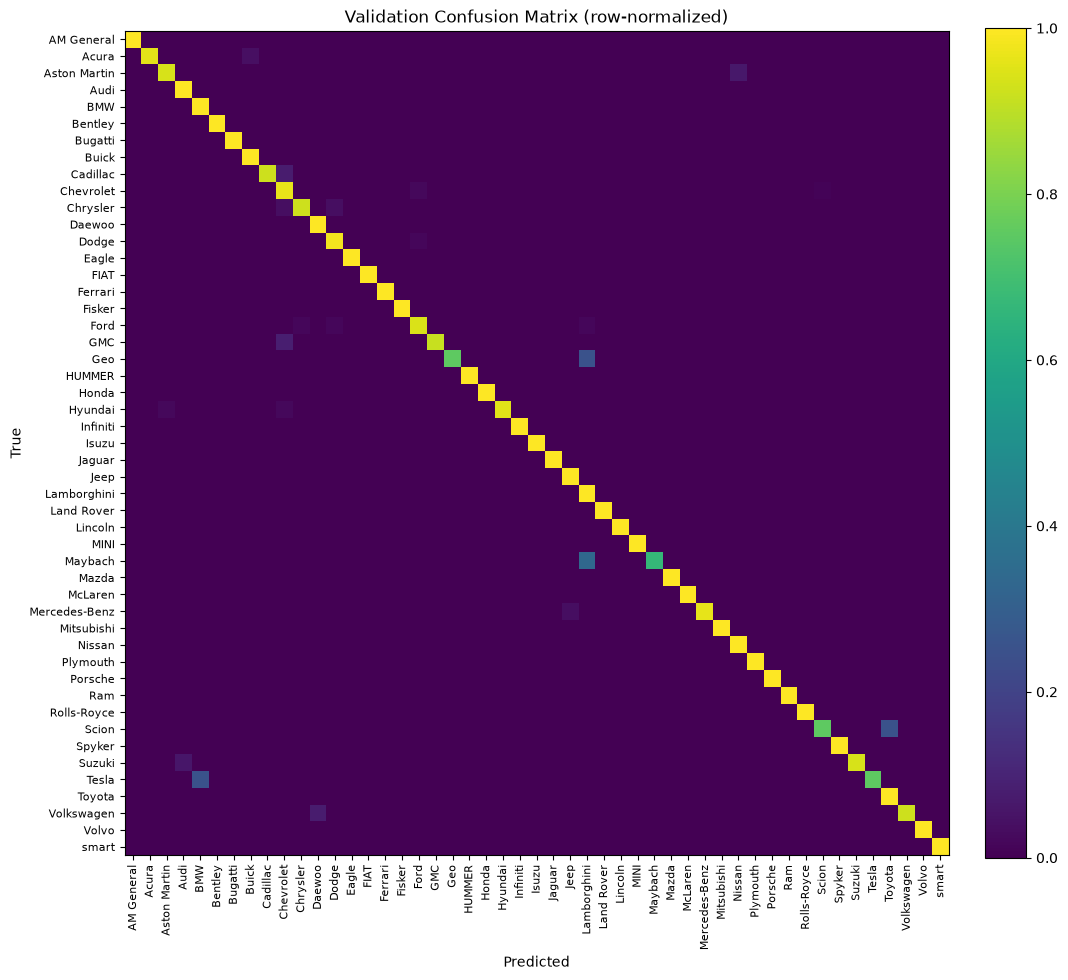

Top confusions (true -> predicted, fraction of true class):
  Maybach -> Lamborghini: 0.33
  Scion -> Toyota: 0.25
  Tesla -> BMW: 0.25
  Geo -> Lamborghini: 0.25
  GMC -> Chevrolet: 0.08
  Volkswagen -> Daewoo: 0.08
  Cadillac -> Chevrolet: 0.08
  Aston Martin -> Nissan: 0.06
  Suzuki -> Audi: 0.06
  Acura -> Buick: 0.04


In [14]:
def plot_confusion_matrix(y_true, y_pred, classes, normalize=True, title='Confusion Matrix'):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(classes))).astype(float)
    if normalize:
        cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)   # row-normalized: diagonal = per-class accuracy
    n = len(classes)
    size = max(10, n * 0.22)                                      # scale figure with number of classes
    fig, ax = plt.subplots(figsize=(size, size))
    im = ax.imshow(cm, cmap='viridis', vmin=0, vmax=1 if normalize else None)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    font = max(4, min(10, 400 / n))
    ax.set_xticks(range(n)); ax.set_xticklabels([str(c) for c in classes], rotation=90, fontsize=font)
    ax.set_yticks(range(n)); ax.set_yticklabels([str(c) for c in classes], fontsize=font)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title)
    if n <= 30:   # numbers only stay readable for a small number of classes
        for i in range(n):
            for j in range(n):
                if cm[i, j] > 0:
                    ax.text(j, i, f'{cm[i, j]:.2f}' if normalize else int(cm[i, j]),
                            ha='center', va='center', fontsize=font * 0.8,
                            color='black' if cm[i, j] > 0.5 else 'white')
    plt.tight_layout()
    plt.show()
    return cm

cm = plot_confusion_matrix(y_true, y_pred, classes, title='Validation Confusion Matrix (row-normalized)')

# Most frequent confusions (off-diagonal)
off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1][:10], off.shape))[0]
print('Top confusions (true -> predicted, fraction of true class):')
for i, j in top:
    if off[i, j] > 0:
        print(f'  {classes[i]} -> {classes[j]}: {off[i, j]:.2f}')

## **5.3 Check Model Inference**

Please write a function, `show_predictions()` which will show:


1.   The top 5 confidenct predicted images with an example each.
2.   The bottom 5 confident predicted images, with an example each.

For each image, show the true label, what your model predicted and with what confidence.



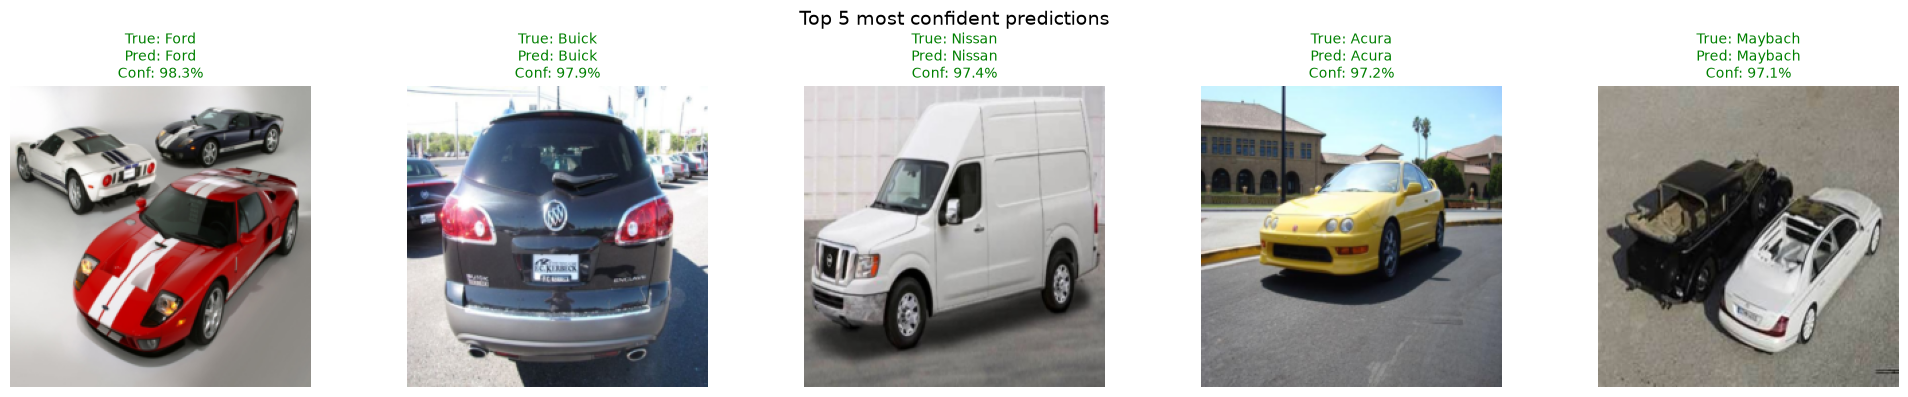

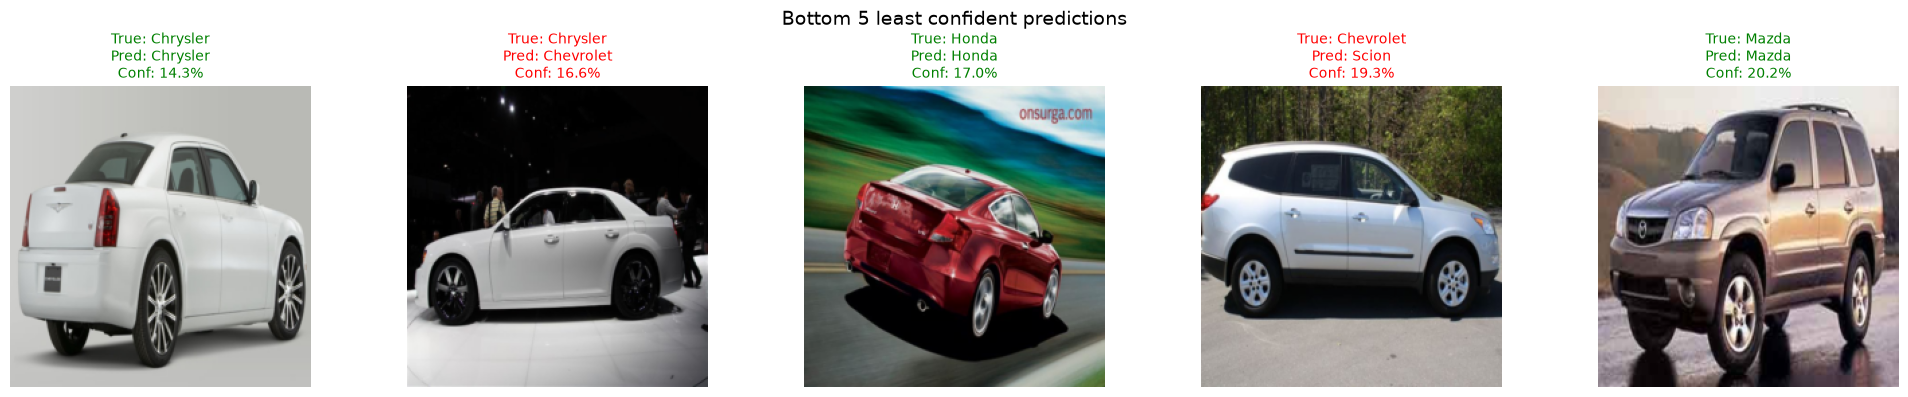

In [15]:
def show_predictions(model, dataset, device, k=5, batch_size=32):
    """Shows the k most confident and k least confident predictions, one example per predicted class."""
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)
    y_true, y_pred, y_prob = get_predictions(model, loader, device)
    conf = y_prob.max(axis=1)

    def pick(order):
        seen, out = set(), []
        for idx in order:
            if y_pred[idx] not in seen:      # one example per (predicted) class
                seen.add(y_pred[idx]); out.append(idx)
            if len(out) == k:
                break
        return out

    top = pick(np.argsort(-conf))
    bottom = pick(np.argsort(conf))

    for name, idxs in [('Top 5 most confident predictions', top), ('Bottom 5 least confident predictions', bottom)]:
        fig, axes = plt.subplots(1, k, figsize=(4 * k, 4))
        fig.suptitle(name, fontsize=14)
        for ax, idx in zip(axes, idxs):
            img, _ = dataset[idx]
            ax.imshow(denormalize(img))
            correct = y_true[idx] == y_pred[idx]
            ax.set_title(f'True: {classes[y_true[idx]]}\nPred: {classes[y_pred[idx]]}\nConf: {conf[idx]:.1%}',
                         color='green' if correct else 'red', fontsize=10)
            ax.axis('off')
        plt.tight_layout()
        plt.show()

show_predictions(model, val_data, device)

## **6. Report**

Please write a report discussing all your choices and procedure to implement your vehicle classifier. In your report, include all your choices (i.e. hyperparameters, lr, models, loss, optimizer) and explain why you made those choices to achieve your performance. Your report must be thorough and comprehensive, please discuss fully how you were able to obtain a high performance. Please also include an analysis of your model, whether it may be overfitting or underfitting or fitting well and what you may have done to further improve your performance.

### Data
- Custom `CarDataSet` reads images + the make CSV; grayscale images are converted to RGB. The class list is built from the training CSV and shared with val/test so label indices always match.
- 10% of the training set is held out (stratified by class) as a validation set for learning curves, checkpoint selection and analysis (7,329 train / 815 val; 8,041 test).
- Images are resized to a square 224×224 instead of center-cropped, because cars are wide and a center crop cuts off the front/rear, which carry the most make-specific detail (grille, badge, lights).
- Augmentation (train only): RandomResizedCrop (scale 0.7–1.0), horizontal flip (a mirrored car is still the same make), TrivialAugmentWide (random color/geometric op each image), RandomErasing (forces the model to use more than one part of the car). ImageNet mean/std normalization to match the pretrained weights.

### Model
- Transfer learning with **ConvNeXt-Tiny** pretrained on ImageNet-1k, final linear layer replaced with a **49**-class head. In Phase 2, fine-tuning the whole pretrained network beat training only the head, and Stanford Cars is fine-grained (small visual differences between classes), so the whole network is fine-tuned. ConvNeXt-Tiny is more accurate than ResNet-18/50 on ImageNet at similar cost and fits on a single GPU at batch size 32 with mixed precision (~27.9M parameters).

### Training setup
| Choice | Value | Why |
|---|---|---|
| Loss | CrossEntropy, label smoothing 0.1 | Reduces over-confidence between near-identical classes |
| Optimizer | AdamW, weight decay 0.05 | Standard for ConvNeXt; decoupled weight decay regularizes |
| LR | backbone 1e-4, head 1e-3 | Pretrained features need small updates; the new head starts random |
| Schedule | 1-epoch linear warmup → cosine decay | Warmup avoids wrecking pretrained weights early; cosine gives a smooth anneal |
| Epochs | 20 | Val accuracy peaked at epoch 15, then plateaued |
| Batch size | 32 | Fits GPU memory at 224px with AMP |
| Other | AMP, grad-clip 1.0, best-val checkpoint | Speed/memory, stability, avoid keeping an overfit final epoch |

### Results
- Best validation accuracy: **97.18%** (epoch 15). Train accuracy at that epoch was **98.10%**; final train accuracy after epoch 20 was **98.62%**.
- Hold-out **test accuracy: 95.83%**.
- Lowest per-class validation recalls: Maybach (0.667), Scion (0.750), Geo (0.750) — all rare classes with few validation examples. Most common confusions: Maybach → Lamborghini, Scion → Toyota, Tesla → BMW, GMC → Chevrolet, Cadillac → Chevrolet — sister brands or cars that share platforms/design language.

### Fit analysis
- Train and validation loss both decreased across training, and validation accuracy rose steadily to 97.18% by epoch 15 then plateaued near 96–97%. The train/val gap stayed small (~98.6% vs ~96.8% at the end), so the model fits well with no clear overfitting.
- Train accuracy is computed on heavily augmented images with label smoothing, so it understates how well the model fits clean training data.

### What could improve it further
- Higher resolution (e.g. 288–320px) — fine details like badges become visible.
- Cropping to the bounding boxes if provided, removing background.
- Larger backbone (ConvNeXt-Small, EfficientNetV2-S), longer training, Mixup/CutMix.
- Test-time augmentation (average predictions over the image and its horizontal flip).
- Ensembling a few models / seeds.


# **7. Loading your model code**

Please provide code to initialize your model, and code to load the model. Please call your model `vehicle_classifier`. This is so we can easily run your model.

Please also provide here your CarDataSet class and loader with option to add a path for the test data images and csv annotations.

You do not need to do anythig else, this code will be used by TAs to load and run your model to grade on test set.

[This link](https://pytorch.org/tutorials/beginner/saving_loading_models.html) will be useful.

In [16]:
# paths
test_images_path = r'C:\ml\stanford_cars\cars_test'           # path to images/test/
test_annotations_path = r'C:\ml\stanford_cars\test_make.csv'  # path to test_make.csv
weights_path = r'vehicle_classifier.pth'                      # path to trained weights

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# load your weights (from weights_path); checkpoint also stores the class list
checkpoint = torch.load(weights_path, map_location=device)
classes = checkpoint['classes']
img_size = checkpoint.get('img_size', 224)

eval_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

test_dataset = CarsDataset(test_images_path, test_annotations_path, transform=eval_transform, classes=classes)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)

# Define model
vehicle_classifier = convnext_tiny(weights=None)
vehicle_classifier.classifier[2] = nn.Linear(vehicle_classifier.classifier[2].in_features, len(classes))

vehicle_classifier.load_state_dict(checkpoint['model_state_dict'])
vehicle_classifier = vehicle_classifier.to(device)
vehicle_classifier.eval()

# Sanity check
correct = total = 0
with torch.no_grad():
    for images, labels in test_loader:
        preds = vehicle_classifier(images.to(device)).argmax(1).cpu()
        correct += (preds == labels).sum().item()
        total += labels.size(0)
print(f'Test accuracy: {100 * correct / total:.2f}%')

Test accuracy: 95.83%


___
___
# End of Phase 3 😊🥳